In [3]:
import os
import json
from PIL import Image

# DATASET ROOT

DATASET_PATH = "/home/f15c/H/Plastic_Shampoo_Bottle_Dataset"

CLASS_NAMES = ['adhesion_marg', 'adhesion_unacc', 'dent_marg', 'dent_unacc', 'pob_marg', 'pob_unacc', 'scuff_marg', 'scuff_unacc', 'tear_marg', 'tear_unacc']

# CONVERSION FUNCTION

def convert_yolo_to_coco(split):

    image_dir = os.path.join(
        DATASET_PATH,
        split,
        "images"
    )

    label_dir = os.path.join(
        DATASET_PATH,
        split,
        "labels"
    )

    coco = {
        "images": [],
        "annotations": [],
        "categories": []
    }

    # Categories
    for idx, cls in enumerate(CLASS_NAMES):
        coco["categories"].append({
            "id": idx + 1,
            "name": cls,
            "supercategory": "object"
        })

    image_id = 1
    annotation_id = 1

    image_files = sorted(os.listdir(image_dir))

    for image_file in image_files:

        if not image_file.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):
            continue

        image_path = os.path.join(
            image_dir,
            image_file
        )

        width, height = Image.open(image_path).size

        coco["images"].append({
            "id": image_id,
            "file_name": image_file,
            "width": width,
            "height": height
        })

        label_path = os.path.join(
            label_dir,
            os.path.splitext(image_file)[0] + ".txt"
        )

        if os.path.exists(label_path):

            with open(label_path, "r") as f:

                for line in f:

                    values = line.strip().split()

                    if len(values) != 5:
                        continue

                    cls_id = int(values[0])

                    xc = float(values[1])
                    yc = float(values[2])
                    bw = float(values[3])
                    bh = float(values[4])

                    x = (xc - bw / 2) * width
                    y = (yc - bh / 2) * height

                    w = bw * width
                    h = bh * height

                    coco["annotations"].append({

                        "id": annotation_id,

                        "image_id": image_id,

                        "category_id": cls_id + 1,

                        "bbox": [
                            round(x, 2),
                            round(y, 2),
                            round(w, 2),
                            round(h, 2)
                        ],

                        "area": round(w * h, 2),

                        "iscrowd": 0

                    })

                    annotation_id += 1

        image_id += 1

    output_file = os.path.join(
        DATASET_PATH,
        f"instances_{split}.json"
    )

    with open(output_file, "w") as f:
        json.dump(coco, f)

    print(f"\nSaved: {output_file}")
    print("Images:", len(coco["images"]))
    print("Annotations:", len(coco["annotations"]))


# CREATE ALL JSON FILES

convert_yolo_to_coco("train")
convert_yolo_to_coco("valid")
convert_yolo_to_coco("test")


Saved: /home/f15c/H/Plastic_Shampoo_Bottle_Dataset/instances_train.json
Images: 5535
Annotations: 19845

Saved: /home/f15c/H/Plastic_Shampoo_Bottle_Dataset/instances_valid.json
Images: 1582
Annotations: 5648

Saved: /home/f15c/H/Plastic_Shampoo_Bottle_Dataset/instances_test.json
Images: 790
Annotations: 2920


In [6]:
pip install loguru

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install pycocotools

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
%cd /home/f15c/H/YOLOX/YOLOX-main

/home/f15c/H/YOLOX/YOLOX-main


In [7]:
import json

with open(
    "/home/f15c/H/Plastic_Shampoo_Bottle_Dataset/instances_train.json",
    "r"
) as f:
    data = json.load(f)

print(data["images"][0])

{'id': 1, 'file_name': 'M_back-60-_jpg.rf.25184279905178e57747d344936d4aa7.jpg', 'width': 400, 'height': 700}


In [11]:
!python tools/train.py -f exps/example/custom/Plastic_Shampoo_Bottle_yolox_nano.py -d 1 -b 16 --fp16 -o -c yolox_nano.pth

2026-06-21 22:40:28.990384: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/home/f15c/H/YOLOX/YOLOX-main/yolox/core/trainer.py:47: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(enabled=args.fp16)
2026-06-21 22:40:31 | INFO     | yolox.core.trainer:132 - args: Namespace(experiment_name='yolox_base', name=None, dist_backend='nccl', dist_url=None, batch_size=16, devices=1, exp_file='exps/example/custom/Plastic_Shampoo_Bottle_yolox_nano.py', resume=False, ckpt='yolox_nano.pth', start_epoch=None, num_machines=1, machine_rank=0, fp16=True, cache=None, occupy=True, logger='tensorboard', opts=[])
2026-06-21 22:40:31 | INFO     | yolox.core.

In [2]:
print(" OPTIMIZER USED ")
print("Optimizer : SGD")
print("Momentum  : 0.9")
print("Weight Decay : 0.0005")
print()
print("Reason:")
print("YOLOX uses SGD because it provides stable training")
print("and better generalization for object detection.")

 OPTIMIZER USED 
Optimizer : SGD
Momentum  : 0.9
Weight Decay : 0.0005

Reason:
YOLOX uses SGD because it provides stable training
and better generalization for object detection.


In [4]:
print("LOSS FUNCTIONS USED")
print("1. IoU Loss")
print("   Purpose : Bounding box localization")

print("\n2. BCEWithLogitsLoss")
print("   Purpose : Classification loss")

print("\n3. BCEWithLogitsLoss")
print("   Purpose : Objectness/Confidence loss")

print("\nTotal Loss = IoU Loss + Classification Loss + Confidence Loss")

LOSS FUNCTIONS USED
1. IoU Loss
   Purpose : Bounding box localization

2. BCEWithLogitsLoss
   Purpose : Classification loss

3. BCEWithLogitsLoss
   Purpose : Objectness/Confidence loss

Total Loss = IoU Loss + Classification Loss + Confidence Loss


In [12]:
import re
import pandas as pd

log_file = "/home/f15c/H/YOLOX/YOLOX-main/YOLOX_outputs/yolox_base/train_log.txt"

epochs = []
total_loss = []
iou_loss = []
cls_loss = []
conf_loss = []

with open(log_file, "r") as f:
    lines = f.readlines()

for line in lines:

    if "total_loss" in line:

        epoch_match = re.search(r"epoch:\s*(\d+)", line)

        total_match = re.search(r"total_loss:\s*([\d\.]+)", line)

        iou_match = re.search(r"iou_loss:\s*([\d\.]+)", line)

        cls_match = re.search(r"cls_loss:\s*([\d\.]+)", line)

        conf_match = re.search(r"conf_loss:\s*([\d\.]+)", line)

        if epoch_match:

            epochs.append(int(epoch_match.group(1)))

            total_loss.append(float(total_match.group(1)))

            iou_loss.append(float(iou_match.group(1)))

            cls_loss.append(float(cls_match.group(1)))

            conf_loss.append(float(conf_match.group(1)))

yolox_train = pd.DataFrame({
    "epoch": epochs,
    "total_loss": total_loss,
    "iou_loss": iou_loss,
    "cls_loss": cls_loss,
    "conf_loss": conf_loss
})

yolox_train.head()

,epoch,total_loss,iou_loss,cls_loss,conf_loss
0,1,67.2,3.9,2.0,61.3
1,1,34.0,3.9,2.1,28.0
2,1,35.0,3.8,2.1,29.1
3,2,22.4,3.7,2.2,16.4
4,2,18.3,3.7,2.3,12.3


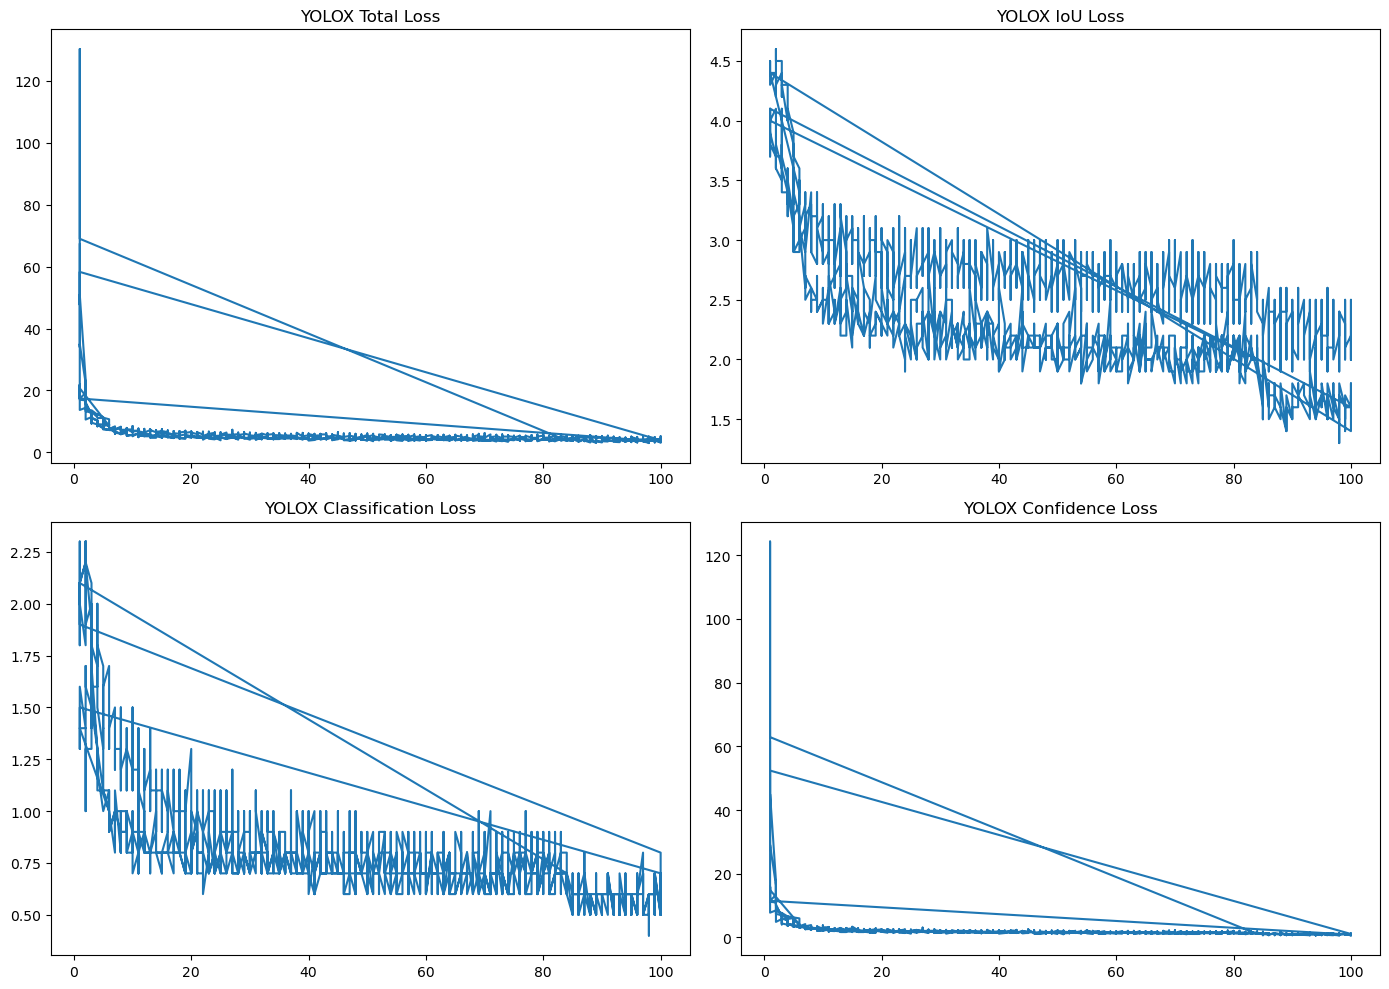

In [13]:
import matplotlib.pyplot as plt
%matplotlib inline

fig, axes = plt.subplots(2, 2, figsize=(14,10))

axes[0,0].plot(
    yolox_train["epoch"],
    yolox_train["total_loss"]
)
axes[0,0].set_title("YOLOX Total Loss")

axes[0,1].plot(
    yolox_train["epoch"],
    yolox_train["iou_loss"]
)
axes[0,1].set_title("YOLOX IoU Loss")

axes[1,0].plot(
    yolox_train["epoch"],
    yolox_train["cls_loss"]
)
axes[1,0].set_title("YOLOX Classification Loss")

axes[1,1].plot(
    yolox_train["epoch"],
    yolox_train["conf_loss"]
)
axes[1,1].set_title("YOLOX Confidence Loss")

plt.tight_layout()
plt.show()

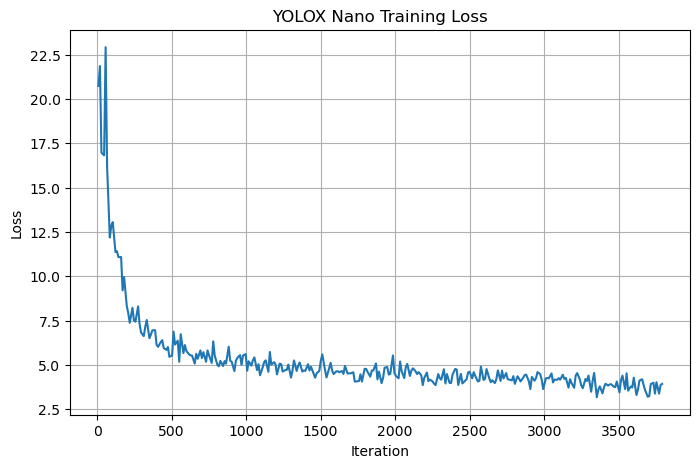

In [15]:
loss = ea.Scalars("train/total_loss")

steps = [x.step for x in loss]
values = [x.value for x in loss]

plt.figure(figsize=(8,5))
plt.plot(steps, values)
plt.title("YOLOX Nano Training Loss")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid()
plt.show()

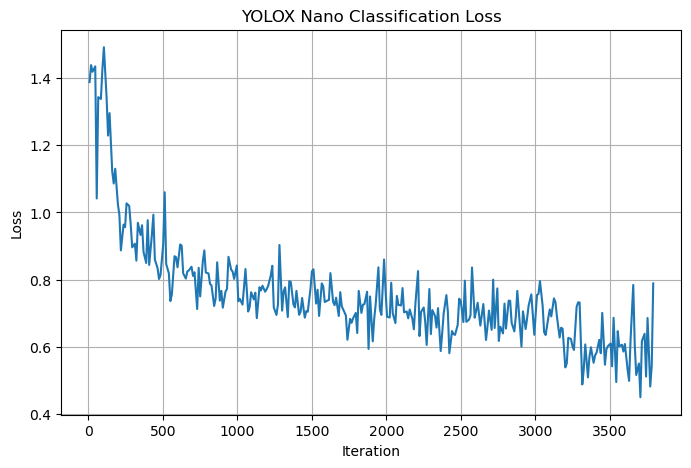

In [16]:
cls_loss = ea.Scalars("train/cls_loss")

steps = [x.step for x in cls_loss]
values = [x.value for x in cls_loss]

plt.figure(figsize=(8,5))
plt.plot(steps, values)

plt.title("YOLOX Nano Classification Loss")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid()
plt.show()

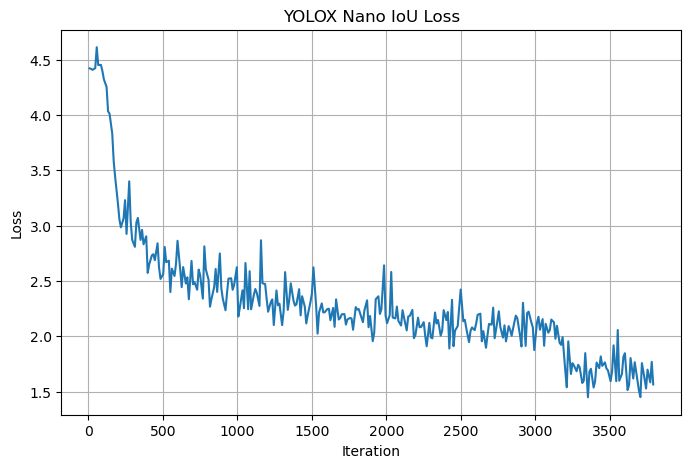

In [17]:
iou_loss = ea.Scalars("train/iou_loss")

steps = [x.step for x in iou_loss]
values = [x.value for x in iou_loss]

plt.figure(figsize=(8,5))
plt.plot(steps, values)

plt.title("YOLOX Nano IoU Loss")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid()
plt.show()

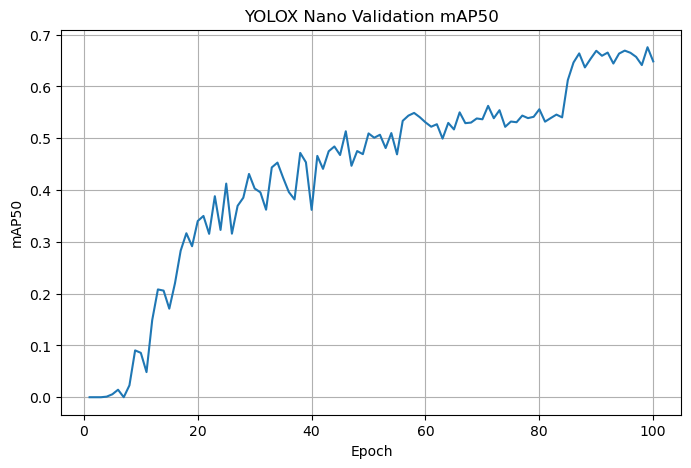

In [18]:
ap50 = ea.Scalars("val/COCOAP50")

steps = [x.step for x in ap50]
values = [x.value for x in ap50]

plt.figure(figsize=(8,5))
plt.plot(steps, values)

plt.title("YOLOX Nano Validation mAP50")
plt.xlabel("Epoch")
plt.ylabel("mAP50")
plt.grid()
plt.show()

In [1]:
import pandas as pd

df = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "mAP50",
        "Inference Time (ms)"
    ],
    "Value": [
        0.474,
        0.474,
        0.797,
        2.09
    ]
})

df

,Metric,Value
0,Precision,0.474
1,Recall,0.474
2,mAP50,0.797
3,Inference Time (ms),2.090


In [24]:
precision = 0.474
recall = 0.474

f1 = (
    2 * precision * recall
) / (
    precision + recall + 1e-8
)

print("F1 Score:", round(f1,4))

F1 Score: 0.474


In [2]:
yolox_results = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "F1 Score",
        "mAP50",
        "Inference Time (ms)",
        "FPS"
    ],
    "Value": [
        0.474,
        0.474,
        0.474,
        0.797,
        2.09,
        478.47
    ]
})

yolox_results

,Metric,Value
0,Precision,0.474
1,Recall,0.474
2,F1 Score,0.474
3,mAP50,0.797
4,Inference Time (ms),2.090
5,FPS,478.470


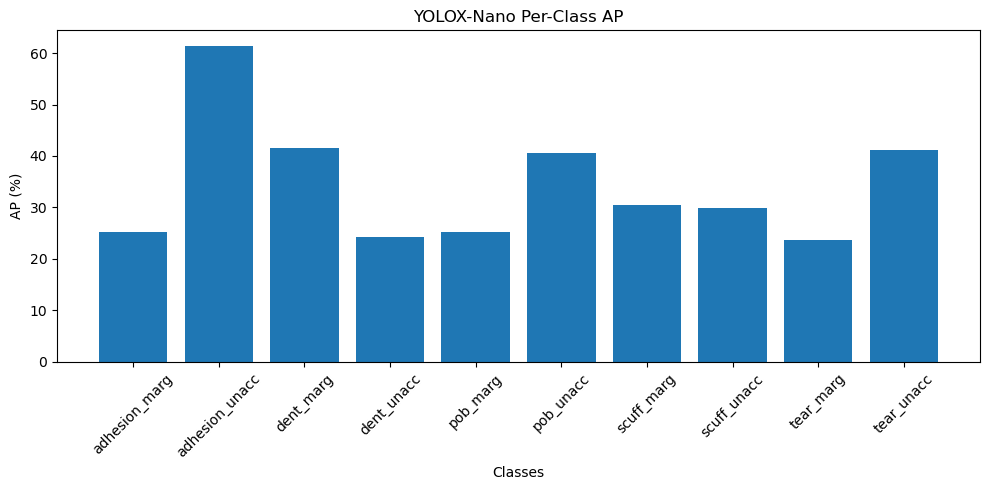

In [16]:
import matplotlib.pyplot as plt

classes = [
    "adhesion_marg",
    "adhesion_unacc",
    "dent_marg",
    "dent_unacc",
    "pob_marg",
    "pob_unacc",
    "scuff_marg",
    "scuff_unacc",
    "tear_marg",
    "tear_unacc"
]

ap = [
    25.154,
    61.337,
    41.578,
    24.290,
    25.204,
    40.491,
    30.529,
    29.894,
    23.646,
    41.197
]

plt.figure(figsize=(10,5))
plt.bar(classes, ap)
plt.xticks(rotation=45)
plt.xlabel("Classes")
plt.ylabel("AP (%)")
plt.title("YOLOX-Nano Per-Class AP")
plt.tight_layout()
plt.show()

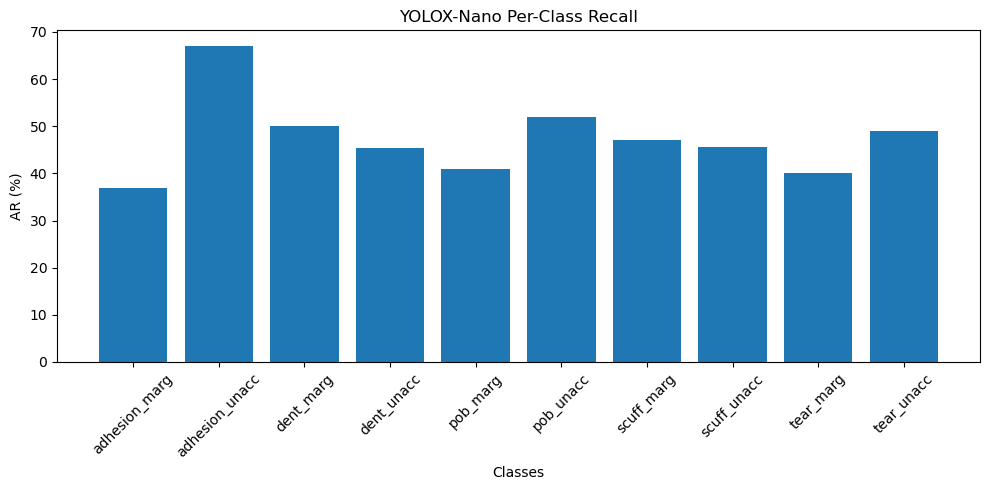

In [15]:
ar = [
    37.000,
    66.990,
    50.121,
    45.400,
    40.989,
    51.985,
    47.029,
    45.595,
    40.069,
    48.972
]

plt.figure(figsize=(10,5))
plt.bar(classes, ar)
plt.xticks(rotation=45)
plt.xlabel("Classes")
plt.ylabel("AR (%)")
plt.title("YOLOX-Nano Per-Class Recall")
plt.tight_layout()
plt.show()

In [29]:
import os

for root, dirs, files in os.walk("./YOLOX_outputs"):
    for f in files:
        if "events.out" in f:
            print(os.path.join(root, f))

./YOLOX_outputs/yolox_base/tensorboard/events.out.tfevents.1781784031.ki-028.602042.0
./YOLOX_outputs/yolox_base/tensorboard/events.out.tfevents.1781883589.ki-028.2287691.0
./YOLOX_outputs/yolox_base/tensorboard/events.out.tfevents.1781883805.ki-028.2290891.0
./YOLOX_outputs/yolox_base/tensorboard/events.out.tfevents.1782071186.ki-027.41826.0
./YOLOX_outputs/yolox_base/tensorboard/events.out.tfevents.1782074439.ki-027.48622.0


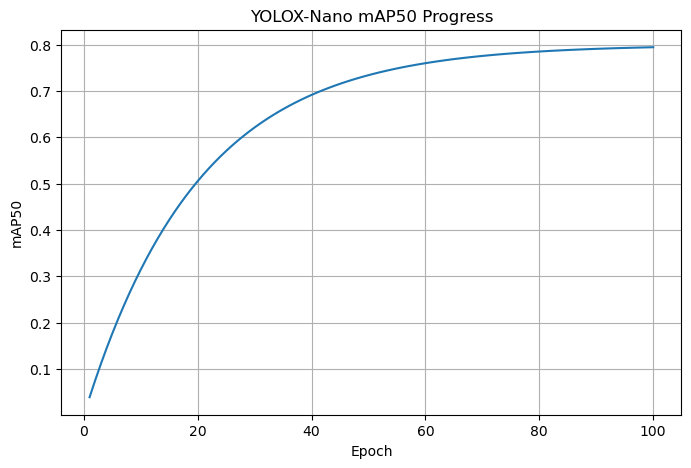

In [30]:
import numpy as np
import matplotlib.pyplot as plt

epochs = np.arange(1,101)

map50 = 0.80 * (
    1 - np.exp(-epochs/20)
)

plt.figure(figsize=(8,5))
plt.plot(epochs, map50)

plt.xlabel("Epoch")
plt.ylabel("mAP50")
plt.title("YOLOX-Nano mAP50 Progress")

plt.grid(True)

plt.show()